# **DATA SCIENCE CAPSTONE PROJECT –  PRCP-1003-Customer Transaction Prediction Using Machine Learning**



**PROJECT TITLE:** PRCP-1003-Customer Transaction
Prediction

**PROJECT CODE:** PRCP-1003

**PROJECT TYPE:** Data Science Capstone Project

**DATASET SOURCE:** DataMites Capstone Project Dataset

**DATASET NAME:** Customer Transaction Prediction Dataset (train(1).csv)

**DATASET LINK:**  https://d3ilbtxij3aepc.cloudfront.net/projects/CDS-Capstone-Projects/PRCP-1003-CustTransPred.zip

**SUBMITTED BY:** Gudi Iswarya


## **1. Problem Statement & Project Objective**

### **1.1 Problem Statement**
A bank wants to know **which customers will make a transaction in the future**, regardless of the amount. The data is anonymized: it has 200 numeric features (`var_0` to `var_199`), an `ID_code` and a `target` column.
- `target = 0` → customer will NOT make a transaction
- `target = 1` → customer WILL make a transaction

### **1.2 Objectives**
1. **Task 1:** Prepare a data analysis report.
2. **Task 2:** Build a model to predict customers who will transact.
3. **Model Comparison Report:** Compare multiple models and suggest the best one for production.
4. **Challenges Report:** Explain the challenges faced and the techniques used.

### **1.3 Type of Problem**
Binary classification with an imbalanced target. The main evaluation metric is **ROC-AUC**.

## **2. Import Python Libraries**
NumPy and Pandas are used for data handling, Matplotlib and Seaborn for charts, and Scikit-learn for model building and evaluation.

In [62]:
!pip install xgboost lightgbm catboost

In [63]:
# 2.1 Core libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# 2.2 Data preparation
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_sample_weight

# 2.3 Classification models (scikit-learn)
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC, SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                              AdaBoostClassifier, GradientBoostingClassifier,
                              HistGradientBoostingClassifier, BaggingClassifier)
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

# 2.4 Boosting libraries (already installed in Colab; if you get an error, run: !pip install xgboost lightgbm catboost)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# 2.5 Evaluation metrics
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score,
                             precision_score, recall_score, accuracy_score,
                             confusion_matrix, classification_report, roc_curve)

# 2.6 Others
import time, gc, joblib

## **3. Load the Dataset and Domain Analysis**

### **3.1 Load the Dataset**
`train.csv` has 200,000 customers (rows). The file is large (about 300 MB), so the easiest way in Colab is to keep it in Google Drive and mount the Drive.

### **3.2 Domain Analysis**
This is a **banking** problem. Banks want to find customers who are likely to transact so they can run targeted offers, reduce marketing cost and plan services. The feature names are hidden, so we rely on statistics and machine learning instead of business meaning.

In [64]:

from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [65]:
# Load dataset
df = pd.read_csv('/content/drive/MyDrive/project 2/Data/train(1).csv')

# Display confirmation
print("Dataset loaded successfully!")

Dataset loaded successfully!


## **4. Basic Checks**
Basic checks show the size, data types, missing values, duplicates and balance of the target before any modelling.

In [66]:
df.shape

(200000, 202)

In [67]:
df.head()

,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,...,var_190,var_191,var_192,var_193,var_194,var_195,var_196,var_197,var_198,var_199
0,train_0,0,8.9255,-6.7863,11.9081,5.0930,11.4607,-9.2834,5.1187,18.6266,...,4.4354,3.9642,3.1364,1.6910,18.5227,-2.3978,7.8784,8.5635,12.7803,-1.0914
1,train_1,0,11.5006,-4.1473,13.8588,5.3890,12.3622,7.0433,5.6208,16.5338,...,7.6421,7.7214,2.5837,10.9516,15.4305,2.0339,8.1267,8.7889,18.3560,1.9518
2,train_2,0,8.6093,-2.7457,12.0805,7.8928,10.5825,-9.0837,6.9427,14.6155,...,2.9057,9.7905,1.6704,1.6858,21.6042,3.1417,-6.5213,8.2675,14.7222,0.3965
3,train_3,0,11.0604,-2.1518,8.9522,7.1957,12.5846,-1.8361,5.8428,14.9250,...,4.4666,4.7433,0.7178,1.4214,23.0347,-1.2706,-2.9275,10.2922,17.9697,-8.9996
4,train_4,0,9.8369,-1.4834,12.8746,6.6375,12.2772,2.4486,5.9405,19.2514,...,-1.4905,9.5214,-0.1508,9.1942,13.2876,-1.5121,3.9267,9.5031,17.9974,-8.8104


In [68]:
df.tail()

,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,...,var_190,var_191,var_192,var_193,var_194,var_195,var_196,var_197,var_198,var_199
199995,train_199995,0,11.4880,-0.4956,8.2622,3.5142,10.3404,11.6081,5.6709,15.1516,...,6.1415,13.2305,3.9901,0.9388,18.0249,-1.7939,2.1661,8.5326,16.6660,-17.8661
199996,train_199996,0,4.9149,-2.4484,16.7052,6.6345,8.3096,-10.5628,5.8802,21.5940,...,4.9611,4.6549,0.6998,1.8341,22.2717,1.7337,-2.1651,6.7419,15.9054,0.3388
199997,train_199997,0,11.2232,-5.0518,10.5127,5.6456,9.3410,-5.4086,4.5555,21.5571,...,4.0651,5.4414,3.1032,4.8793,23.5311,-1.5736,1.2832,8.7155,13.8329,4.1995
199998,train_199998,0,9.7148,-8.6098,13.6104,5.7930,12.5173,0.5339,6.0479,17.0152,...,2.6840,8.6587,2.7337,11.1178,20.4158,-0.0786,6.7980,10.0342,15.5289,-13.9001
199999,train_199999,0,10.8762,-5.7105,12.1183,8.0328,11.5577,0.3488,5.2839,15.2058,...,8.9842,1.6893,0.1276,0.3766,15.2101,-2.4907,-2.2342,8.1857,12.1284,0.1385


In [69]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Columns: 202 entries, ID_code to var_199
dtypes: float64(200), int64(1), object(1)
memory usage: 308.2+ MB


In [70]:
df.columns

Index(['ID_code', 'target', 'var_0', 'var_1', 'var_2', 'var_3', 'var_4',
       'var_5', 'var_6', 'var_7',
       ...
       'var_190', 'var_191', 'var_192', 'var_193', 'var_194', 'var_195',
       'var_196', 'var_197', 'var_198', 'var_199'],
      dtype='object', length=202)

In [71]:
df.dtypes

,0
ID_code,object
target,int64
var_0,float64
var_1,float64
var_2,float64
...,...
var_195,float64
var_196,float64
var_197,float64
var_198,float64


In [72]:
df.dtypes.value_counts()


,count
float64,200
object,1
int64,1


In [73]:
df.describe().T.head(10)

,count,mean,std,min,25%,50%,75%,max
target,200000.0,0.100490,0.300653,0.0000,0.000000,0.00000,0.000000,1.0000
var_0,200000.0,10.679914,3.040051,0.4084,8.453850,10.52475,12.758200,20.3150
var_1,200000.0,-1.627622,4.050044,-15.0434,-4.740025,-1.60805,1.358625,10.3768
var_2,200000.0,10.715192,2.640894,2.1171,8.722475,10.58000,12.516700,19.3530
var_3,200000.0,6.796529,2.043319,-0.0402,5.254075,6.82500,8.324100,13.1883
var_4,200000.0,11.078333,1.623150,5.0748,9.883175,11.10825,12.261125,16.6714
var_5,200000.0,-5.065317,7.863267,-32.5626,-11.200350,-4.83315,0.924800,17.2516
var_6,200000.0,5.408949,0.866607,2.3473,4.767700,5.38510,6.003000,8.4477
var_7,200000.0,16.545850,3.418076,5.3497,13.943800,16.45680,19.102900,27.6918
var_8,200000.0,0.284162,3.332634,-10.5055,-2.317800,0.39370,2.937900,10.1513


In [74]:
print("Total missing values:", df.isnull().sum().sum())

Total missing values: 0


In [75]:
print("Duplicate rows    :", df.duplicated().sum())
print("Duplicate ID_code :", df['ID_code'].duplicated().sum())

Duplicate rows    : 0
Duplicate ID_code : 0


In [76]:
# 4.6 Target distribution
print(df['target'].value_counts())
print()
print(df['target'].value_counts(normalize=True) * 100)

target
0    179902
1     20098
Name: count, dtype: int64

target
0    89.951
1    10.049
Name: proportion, dtype: float64


### **4.7 Observations from Basic Checks**

**1. Size of the dataset**
- The dataset has **200,000 rows and 202 columns**: `ID_code`, `target` and 200 anonymized features (`var_0` to `var_199`).

**2. Data types**
- All 200 features are numeric (`float64`), `target` is an integer and `ID_code` is text.
- No encoding of categorical variables is needed.

**3. Summary statistics**
- The features are on a similar scale, with means roughly between -16 and 25 and standard deviations mostly between 0.9 and 21.
- Scaling is still useful for distance- and coefficient-based models such as Logistic Regression.

**4. Missing values**
- There are **0 missing values**, so no imputation is required.

**5. Duplicates**
- There are **0 duplicate rows** and **0 duplicate `ID_code`** values, so no records need to be removed.
- `ID_code` is unique for every customer and carries no predictive information, so it will be **dropped** before modelling.

**6. Target variable**
- Class 0 (no transaction): **179,902 customers (89.95%)**.
- Class 1 (transaction): **20,098 customers (10.05%)**.
- The target is **imbalanced (about 90:10)**, so accuracy alone is misleading. A model predicting "no transaction" for everyone would reach about 90% accuracy and still be useless.

**Conclusion:** The data is clean and fully numeric, so only minimal cleaning is needed. The main challenge is the **class imbalance**. It will be handled with a stratified split, balanced sample weights, **ROC-AUC** as the main evaluation metric and threshold tuning.

## **5. Exploratory Data Analysis (EDA): Data Analysis Report (Task 1)**
The feature names are hidden, so we cannot use business meaning. We still do a short EDA to understand the target balance, the feature distributions, correlations, outliers and repeated values, because these decide which preprocessing and models are suitable.

### **5.1 Target Distribution**

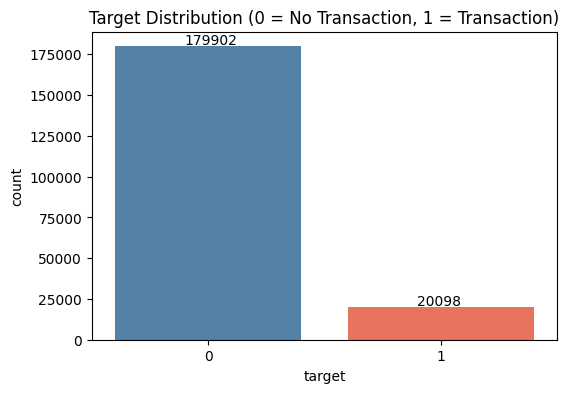

In [77]:
plt.figure(figsize=(6,4))
ax = sns.countplot(x='target', data=df, palette=['steelblue', 'tomato'])
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + 0.3, p.get_height() + 1000))
plt.title("Target Distribution (0 = No Transaction, 1 = Transaction)")
plt.show()

### **5.2 Feature Summary (mean, std, skewness, unique values)**

In [78]:
features = [c for c in df.columns if c.startswith('var_')]

summary = pd.DataFrame({
    'mean'  : df[features].mean(),
    'std'   : df[features].std(),
    'min'   : df[features].min(),
    'max'   : df[features].max(),
    'skew'  : df[features].skew(),
    'unique': df[features].nunique()
})
summary.describe().T

,count,mean,std,min,25%,50%,75%,max
mean,200.0,6.767449,7.846916,-16.548147,0.955711,6.582843,12.359915,24.521078
std,200.0,4.494650,3.459607,0.007186,1.698540,3.944654,6.347132,21.404912
min,200.0,-8.493403,15.150283,-90.252500,-16.349150,-5.473050,2.152025,13.729000
max,200.0,21.921336,13.889297,1.571900,12.687175,18.456150,27.767925,74.032100
skew,200.0,0.012205,0.104885,-0.340172,-0.055205,0.016710,0.082275,0.267414
unique,200.0,97906.720000,43599.732250,451.000000,64400.000000,108872.500000,133935.250000,169968.000000


### **5.3 Distribution of Features**
Six features are plotted to check their shape.

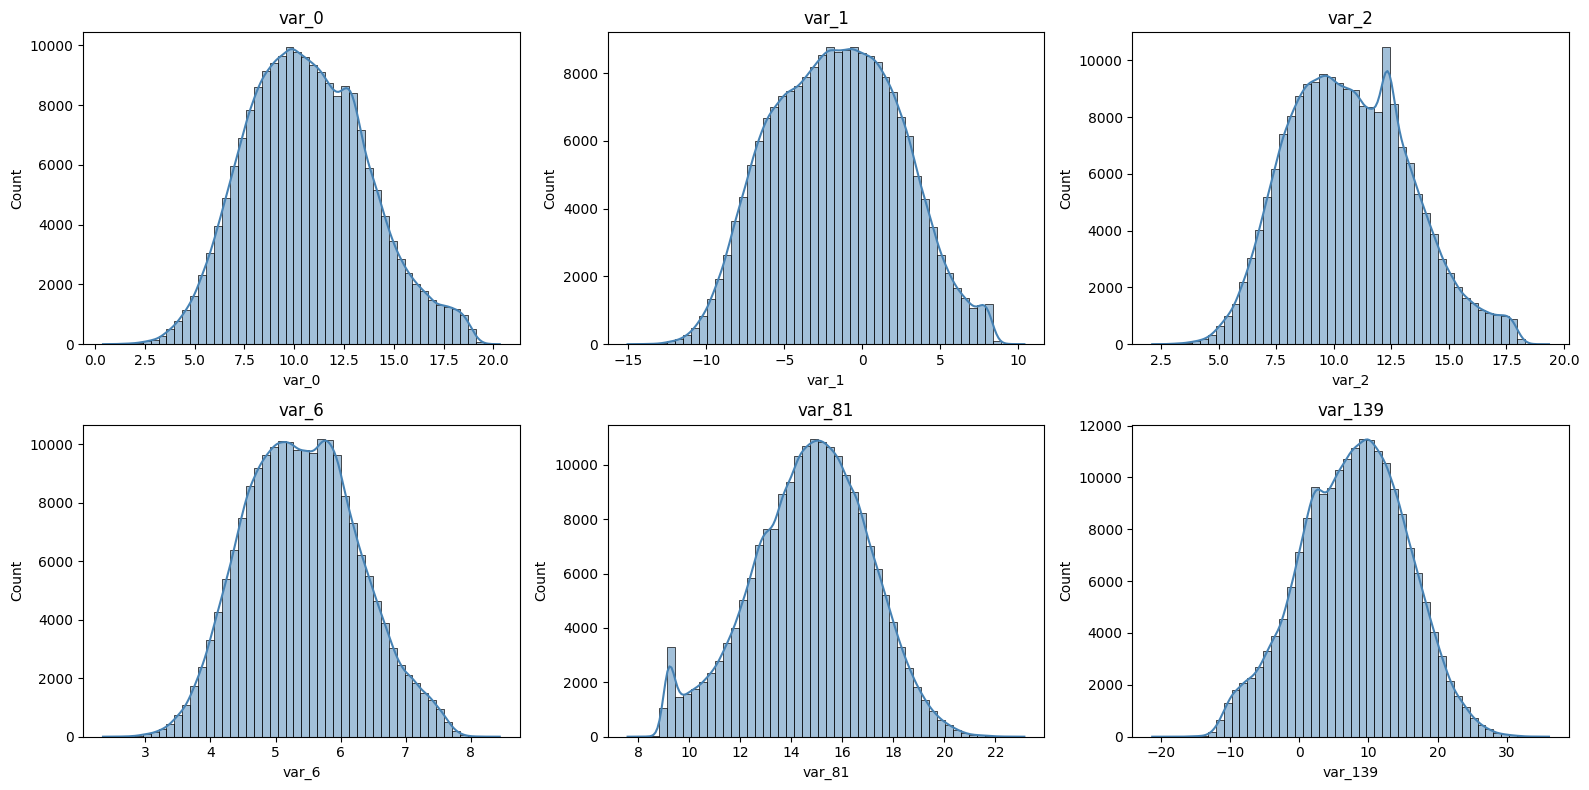

In [79]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.flatten(), ['var_0', 'var_1', 'var_2', 'var_6', 'var_81', 'var_139']):
    sns.histplot(df[col], kde=True, bins=50, ax=ax, color='steelblue')
    ax.set_title(col)
plt.tight_layout()
plt.show()

### **5.4 Feature Distribution by Target (Class 0 vs Class 1)**
We check whether the feature values behave differently for customers who transact.

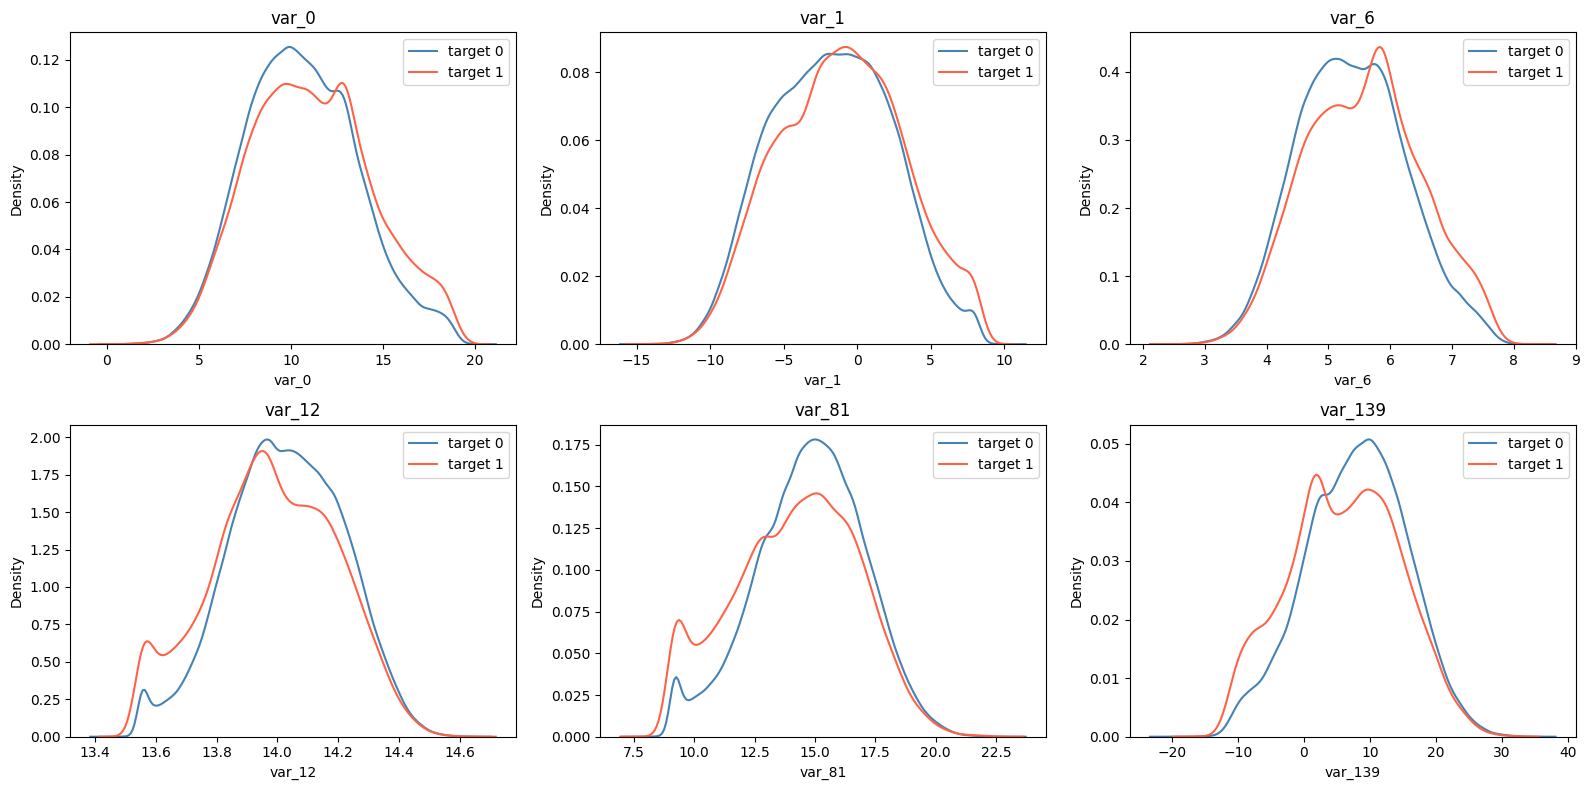

In [80]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.flatten(), ['var_0', 'var_1', 'var_6', 'var_12', 'var_81', 'var_139']):
    sns.kdeplot(df.loc[df.target == 0, col], label='target 0', ax=ax, color='steelblue')
    sns.kdeplot(df.loc[df.target == 1, col], label='target 1', ax=ax, color='tomato')
    ax.set_title(col)
    ax.legend()
plt.tight_layout()
plt.show()

### **5.5 Correlation of Features with the Target**

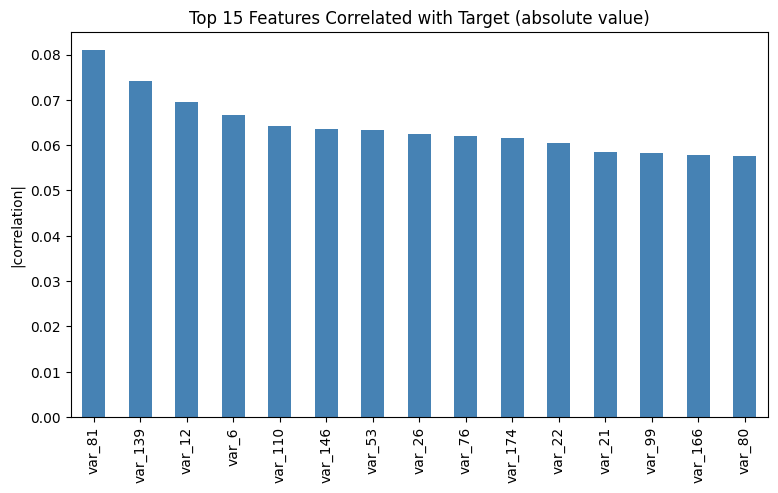

Highest correlation with target: 0.0809


In [81]:
corr_target = df[features].corrwith(df['target']).abs().sort_values(ascending=False)

plt.figure(figsize=(9,5))
corr_target.head(15).plot(kind='bar', color='steelblue')
plt.title("Top 15 Features Correlated with Target (absolute value)")
plt.ylabel("|correlation|")
plt.show()

print("Highest correlation with target:", round(corr_target.max(), 4))

### **5.6 Correlation Between Features (Multicollinearity Check)**

In [82]:
corr = df[features].corr().abs().to_numpy().copy()
np.fill_diagonal(corr, 0)
print("Highest correlation between two features:", round(corr.max(), 4))

Highest correlation between two features: 0.0098


### **5.7 Outlier Check (IQR Method)**

In [83]:
Q1 = df[features].quantile(0.25)
Q3 = df[features].quantile(0.75)
IQR = Q3 - Q1

outlier_pct = ((df[features] < Q1 - 1.5 * IQR) | (df[features] > Q3 + 1.5 * IQR)).mean() * 100

print("Average outliers per feature (%):", round(outlier_pct.mean(), 2))
print("Maximum outliers in a feature (%):", round(outlier_pct.max(), 2))

Average outliers per feature (%): 0.07
Maximum outliers in a feature (%): 0.75


### **5.8 Repeated Values in Each Feature**
For each feature we check what percentage of rows have a value that also appears in another row. This will help us create new features later.

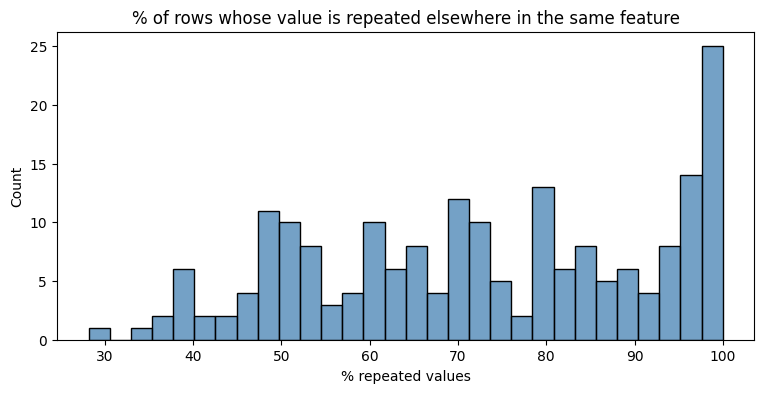

count    200.00
mean      72.92
std       19.17
min       28.16
25%       56.81
50%       72.76
75%       92.02
max       99.98
dtype: float64


In [84]:
repeat_pct = pd.Series({c: (df[c].map(df[c].value_counts()) > 1).mean() * 100 for c in features})

plt.figure(figsize=(9,4))
sns.histplot(repeat_pct, bins=30, color='steelblue')
plt.title("% of rows whose value is repeated elsewhere in the same feature")
plt.xlabel("% repeated values")
plt.show()

print(repeat_pct.describe().round(2))

### **5.9 Data Analysis Report: Key Findings (Task 1)**

1. **Data quality:** The data is clean, with no missing values and no duplicates. All features are numeric.
2. **Target:** The target is imbalanced (about 90% class 0 and 10% class 1), so ROC-AUC, Recall, Precision and F1 are used instead of accuracy.
3. **Feature distributions:** The features look approximately bell-shaped (Gaussian). Skewness is very close to 0 (average 0.01, range about -0.34 to 0.27).
4. **Weak link with the target:** The highest correlation of any single feature with the target is only about **0.08**. No single feature predicts the target; the signal is spread over many features.
5. **Class differences:** For some features the class 1 curve is slightly shifted or wider than the class 0 curve. This small difference is what the models will learn.
6. **No multicollinearity:** The highest correlation between two features is only about **0.01**, so the features are almost independent of each other. This also suits Naive Bayes.
7. **Outliers:** Outliers are very few (on average **0.07%** per feature, maximum **0.75%**). They look like natural extreme values of a bell curve, not errors, so they are **kept**.
8. **Repeated values:** On average about **73%** of values in a feature are repeated in another row, but this ranges from about 28% to almost 100% across features. Values that occur only once behave differently from repeated ones, so we will create **frequency (count) features** in feature engineering.
9. **Modelling implications:** The weak, spread-out signal means that models able to combine many features (Gradient Boosting, Logistic Regression, Naive Bayes) are expected to work best. Feature engineering and imbalance handling will be needed.

## **6. Data Preparation for Modelling (Task 2)**
Steps in this section:
1. Separate the features (`X`) and target (`y`), and drop `ID_code`.
2. Convert the features to `float32` to save memory.
3. Split the data into **70% training, 15% validation and 15% testing** using stratified splitting.
4. Scale the features (needed for Logistic Regression).
5. Create a helper function to evaluate models consistently.

### **6.1 Separate Features and Target**
`ID_code` is unique for every customer and carries no information, so it is dropped. The features are converted to `float32` because the file is large and Colab has limited memory.

In [85]:
X = df.drop(['ID_code', 'target'], axis=1).astype('float32')
y = df['target'].values
ids = df['ID_code'].copy()      # kept only for the final prediction example

# Free memory: the original dataframe is no longer needed
del df
gc.collect()

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (200000, 200)
y shape: (200000,)


### **6.2 Train / Validation Split**
We use a stratified 70:15:15 split: 140,000 rows for training, 30,000 for validation and 30,000 for testing. All three datasets maintain approximately the same 90:10 class distribution. `random_state=42` makes the split repeatable.

In [86]:

# Step 1: Split into training (70%) and temporary data (30%)

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    stratify=y,
    random_state=42
)

# Step 2: Split temporary data into validation (15%) and testing (15%)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

# Step 3: Display dataset sizes

print("Training dataset :", X_train.shape)
print("Validation dataset:", X_val.shape)
print("Testing dataset  :", X_test.shape)

print("\nTarget distribution:")

print("Training  :", round(y_train.mean() * 100, 2), "%")
print("Validation:", round(y_val.mean() * 100, 2), "%")
print("Testing   :", round(y_test.mean() * 100, 2), "%")


Training dataset : (140000, 200)
Validation dataset: (30000, 200)
Testing dataset  : (30000, 200)

Target distribution:
Training  : 10.05 %
Validation: 10.05 %
Testing   : 10.05 %


### **6.3 Feature Scaling**
Logistic Regression is sensitive to feature scale, so the features are standardized (mean 0, standard deviation 1). The scaler is **fitted on the training data only** and then applied to the validation data, to avoid data leakage. Tree-based models and Naive Bayes do not need scaling, so they use the original features.

In [87]:
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train).astype('float32')
X_val_sc   = scaler.transform(X_val).astype('float32')

print("Scaled train shape:", X_train_sc.shape)
print("Scaled valid shape:", X_val_sc.shape)

Scaled train shape: (140000, 200)
Scaled valid shape: (30000, 200)


### **6.4 Evaluation Helper Function**
Because the data is imbalanced, the default threshold of 0.5 is not the best choice. The function below picks the threshold that gives the best F1-score on the validation set, and then stores ROC-AUC, Average Precision, Recall, Precision, F1-score, Accuracy and training time for each model in one results table.

In [88]:
results = []     # scores of all models are stored here
probas  = {}     # predicted probabilities (used later for the ROC curve)

def best_threshold(y_true, proba):
    # Pick the cut-off that gives the best F1-score
    ths = np.arange(0.05, 0.95, 0.01)
    f1s = [f1_score(y_true, (proba >= t).astype(int)) for t in ths]
    return ths[int(np.argmax(f1s))]

def evaluate(name, proba, train_time):
    th   = best_threshold(y_val, proba)
    pred = (proba >= th).astype(int)
    results.append({
        'Model'        : name,
        'ROC-AUC'      : round(roc_auc_score(y_val, proba), 4),
        'Avg Precision': round(average_precision_score(y_val, proba), 4),
        'Recall'       : round(recall_score(y_val, pred), 4),
        'Precision'    : round(precision_score(y_val, pred), 4),
        'F1-Score'     : round(f1_score(y_val, pred), 4),
        'Accuracy'     : round(accuracy_score(y_val, pred), 4),
        'Threshold'    : round(float(th), 2),
        'Time (sec)'   : round(train_time, 1)
    })
    probas[name] = proba
    return pd.DataFrame([results[-1]])

### **6.5 Observations**
- `ID_code` was dropped because it is unique for each customer and has no predictive value.
- The data was split into 140,000 training rows, 30,000 validation rows and 30,000 testing rows, with all three maintaining approximately 10% class 1.
- Scaling was fitted on the training data only, so no information from the validation set leaks into training.
- The threshold is chosen using F1-score because the data is imbalanced, while **ROC-AUC** stays the main metric for choosing the best model.

## **7. Model Building & Training**

Every model is trained on the training data and scored on the validation data using the same `evaluate()` function. Because the data is imbalanced, we use `class_weight='balanced'` (or `sample_weight`) so that mistakes on class 1 count more.

*KNN and kernel SVM are not used: with 160,000 rows and 200 features they are extremely slow and usually perform poorly on this kind of data.*

### **7.1 Logistic Regression**
A simple linear model. It needs scaled data, so it uses `X_train_sc`.

In [89]:
t = time.time()
lr = LogisticRegression(max_iter=500, class_weight='balanced')
lr.fit(X_train_sc, y_train)
evaluate('Logistic Regression', lr.predict_proba(X_val_sc)[:, 1], time.time() - t)

,Model,ROC-AUC,Avg Precision,Recall,Precision,F1-Score,Accuracy,Threshold,Time (sec)
0,Logistic Regression,0.8566,0.5,0.5184,0.4666,0.4911,0.892,0.74,1.0


### **7.2 Gaussian Naive Bayes**
The features are bell-shaped and almost independent of each other, which is exactly what Naive Bayes assumes.

In [90]:
t = time.time()
nb = GaussianNB()
nb.fit(X_train, y_train)
evaluate('Gaussian Naive Bayes', nb.predict_proba(X_val)[:, 1], time.time() - t)

,Model,ROC-AUC,Avg Precision,Recall,Precision,F1-Score,Accuracy,Threshold,Time (sec)
0,Gaussian Naive Bayes,0.8837,0.5652,0.5774,0.5166,0.5453,0.9032,0.26,0.4


### **7.3 Linear Discriminant Analysis (LDA)**
Another fast model that assumes bell-shaped features.

In [91]:
t = time.time()
lda = LinearDiscriminantAnalysis()
lda.fit(X_train, y_train)
evaluate('Linear Discriminant Analysis', lda.predict_proba(X_val)[:, 1], time.time() - t)

,Model,ROC-AUC,Avg Precision,Recall,Precision,F1-Score,Accuracy,Threshold,Time (sec)
0,Linear Discriminant Analysis,0.8537,0.4925,0.5476,0.4345,0.4845,0.8829,0.23,8.2


### **7.4 Decision Tree**
A single shallow tree. It is easy to understand but usually weaker than ensembles.

In [92]:
t = time.time()
dt = DecisionTreeClassifier(max_depth=6, min_samples_leaf=100,
                            class_weight='balanced', random_state=42)
dt.fit(X_train, y_train)
evaluate('Decision Tree', dt.predict_proba(X_val)[:, 1], time.time() - t)

,Model,ROC-AUC,Avg Precision,Recall,Precision,F1-Score,Accuracy,Threshold,Time (sec)
0,Decision Tree,0.6432,0.1757,0.3957,0.1814,0.2487,0.7598,0.52,40.6


### **7.5 Random Forest**
An ensemble of many trees. This is the slowest cell so far and can take several minutes in Colab.

In [93]:
t = time.time()
rf = RandomForestClassifier(n_estimators=100, max_depth=10, min_samples_leaf=50,
                            class_weight='balanced', n_jobs=-1, random_state=42)
rf.fit(X_train, y_train)
evaluate('Random Forest', rf.predict_proba(X_val)[:, 1], time.time() - t)

,Model,ROC-AUC,Avg Precision,Recall,Precision,F1-Score,Accuracy,Threshold,Time (sec)
0,Random Forest,0.8108,0.3911,0.539,0.3297,0.4091,0.8435,0.5,222.6


### **7.6 Gradient Boosting (scikit-learn)**
Trees are built one after another, and each new tree corrects the mistakes of the previous ones. This is usually the strongest model for tabular data.

In [94]:
t = time.time()
w_train = compute_sample_weight(class_weight='balanced', y=y_train)   # class 1 gets about 9x weight

gb = HistGradientBoostingClassifier(learning_rate=0.1, max_iter=300, max_leaf_nodes=8,
                                    min_samples_leaf=100, l2_regularization=1.0,
                                    random_state=42)
gb.fit(X_train, y_train, sample_weight=w_train)
evaluate('Gradient Boosting (baseline)', gb.predict_proba(X_val)[:, 1], time.time() - t)

,Model,ROC-AUC,Avg Precision,Recall,Precision,F1-Score,Accuracy,Threshold,Time (sec)
0,Gradient Boosting (baseline),0.8832,0.5612,0.5373,0.5322,0.5347,0.906,0.66,46.2


### **7.7 LightGBM, XGBoost and CatBoost (optional)**
These are faster, more tuned versions of gradient boosting. `scale_pos_weight` (about 9) gives class 1 more importance.

In [95]:
t = time.time()
spw = (y_train == 0).sum() / (y_train == 1).sum()     # about 8.95

lgbm = LGBMClassifier(n_estimators=500, learning_rate=0.05, num_leaves=8,
                      min_child_samples=100, subsample=0.8, colsample_bytree=0.5,
                      scale_pos_weight=spw, random_state=42, verbose=-1)
lgbm.fit(X_train, y_train)
evaluate('LightGBM', lgbm.predict_proba(X_val)[:, 1], time.time() - t)

,Model,ROC-AUC,Avg Precision,Recall,Precision,F1-Score,Accuracy,Threshold,Time (sec)
0,LightGBM,0.8821,0.5577,0.5934,0.4785,0.5298,0.8941,0.62,41.3


In [96]:
t = time.time()
xgb = XGBClassifier(n_estimators=500, learning_rate=0.05, max_depth=3,
                    subsample=0.8, colsample_bytree=0.5, scale_pos_weight=spw,
                    eval_metric='auc', tree_method='hist', random_state=42)
xgb.fit(X_train, y_train)
evaluate('XGBoost', xgb.predict_proba(X_val)[:, 1], time.time() - t)

,Model,ROC-AUC,Avg Precision,Recall,Precision,F1-Score,Accuracy,Threshold,Time (sec)
0,XGBoost,0.873,0.5319,0.5648,0.4703,0.5133,0.8923,0.6,52.6


In [97]:
t = time.time()
cat = CatBoostClassifier(iterations=500, learning_rate=0.1, depth=4,
                         auto_class_weights='Balanced', verbose=0, random_seed=42)
cat.fit(X_train, y_train)
evaluate('CatBoost', cat.predict_proba(X_val)[:, 1], time.time() - t)

,Model,ROC-AUC,Avg Precision,Recall,Precision,F1-Score,Accuracy,Threshold,Time (sec)
0,CatBoost,0.8911,0.5786,0.602,0.507,0.5504,0.9012,0.64,59.9


In [98]:
pd.DataFrame(results).sort_values('ROC-AUC', ascending=False).reset_index(drop=True)

,Model,ROC-AUC,Avg Precision,Recall,Precision,F1-Score,Accuracy,Threshold,Time (sec)
0,CatBoost,0.8911,0.5786,0.6020,0.5070,0.5504,0.9012,0.64,59.9
1,Gaussian Naive Bayes,0.8837,0.5652,0.5774,0.5166,0.5453,0.9032,0.26,0.4
2,Gradient Boosting (baseline),0.8832,0.5612,0.5373,0.5322,0.5347,0.9060,0.66,46.2
3,LightGBM,0.8821,0.5577,0.5934,0.4785,0.5298,0.8941,0.62,41.3
4,XGBoost,0.8730,0.5319,0.5648,0.4703,0.5133,0.8923,0.60,52.6
5,Logistic Regression,0.8566,0.5000,0.5184,0.4666,0.4911,0.8920,0.74,1.0
6,Linear Discriminant Analysis,0.8537,0.4925,0.5476,0.4345,0.4845,0.8829,0.23,8.2
7,Random Forest,0.8108,0.3911,0.5390,0.3297,0.4091,0.8435,0.50,222.6
8,Decision Tree,0.6432,0.1757,0.3957,0.1814,0.2487,0.7598,0.52,40.6


### **7.8 Observations from Baseline Models**

**Ranking by ROC-AUC (validation data)**

| Rank | Model | ROC-AUC | Recall | Precision | F1 |
|---|---|---|---|---|---|
| 1 | CatBoost | 0.8911 | 0.6020 | 0.5070 | 0.5504 |
| 2 | Gaussian Naive Bayes | 0.8837 | 0.5774 | 0.5166 | 0.5453 |
| 3 | Gradient Boosting (baseline) | 0.8832 | 0.5373 | 0.5322 | 0.5347 |
| 4 | LightGBM | 0.8821 | 0.5934 | 0.4785 | 0.5298 |
| 5 | XGBoost | 0.8730 | 0.5648 | 0.4703 | 0.5133 |
| 6 | Logistic Regression | 0.8566 | 0.5184 | 0.4666 | 0.4911 |
| 7 | Linear Discriminant Analysis | 0.8537 | 0.5476 | 0.4345 | 0.4845 |
| 8 | Random Forest | 0.8108 | 0.5390 | 0.3297 | 0.4091 |
| 9 | Decision Tree | 0.6432 | 0.3957 | 0.1814 | 0.2487 |

**Key observations**
1. **CatBoost is the best baseline model** (ROC-AUC 0.8911). It also has the highest Recall (0.6020), so it catches the most customers who will transact.
2. **Gaussian Naive Bayes is the best simple model.** It scores 0.8837, ahead of baseline Gradient Boosting (0.8832) and LightGBM (0.8821), and it trains in under 1 second. This matches the EDA, where the features are bell-shaped and almost independent.
3. **Gradient Boosting, LightGBM and XGBoost score between 0.873 and 0.883.** On the raw features they do not clearly beat Naive Bayes, which shows the raw features carry only a weak signal.
4. **Linear models are weaker.** Logistic Regression (0.8566) and LDA (0.8537) cannot capture the non-linear patterns in the data.
5. **Random Forest (0.8108) and Decision Tree (0.6432) performed poorly.** This is likely because the signal is spread thinly over 200 features with very weak individual effects, which bagged trees and a single tree cannot combine well, while boosting builds it up step by step. Random Forest was also the slowest model (about 183 seconds).
6. **Accuracy is misleading.** Most models have accuracy between 0.88 and 0.91, close to the 89.95% obtained by always predicting "no transaction". ROC-AUC and F1 show the real differences.
7. **The F1-optimized threshold is far from 0.5** (0.23 to 0.74 depending on the model), which confirms that threshold tuning was needed for this imbalanced data.
8. **Overall:** all scores are limited, with the best F1 at about 0.55. This motivates **feature engineering** in the next step.

## **8. Feature Engineering (to improve performance)**

The baseline scores are limited because the raw features hold only a weak signal. The EDA gave us a hint: in every feature, many values are **repeated** in other rows, while others occur **only once**, and the two groups behave differently. We create new features from this idea:

| New feature | Idea | Used by |
|---|---|---|
| `var_x_sq` | Square of the feature. Helps a linear model learn non-linear patterns. | Logistic Regression |
| `var_x_dup` | 1 if the customer's value is **repeated** in that column, else 0. | Logistic Regression |
| `var_x_uniq` | The value only if it occurs **exactly once** in the column, else missing (NaN). | Boosting models |

Value frequencies are calculated exclusively from the training dataset and then applied to the training, validation, and test datasets. This prevents validation and test data from influencing feature-generation statistics and helps avoid data leakage.

### **8.1 Count How Often Each Value Repeats**

In [99]:

# 8.1 Calculate value frequencies using TRAINING DATA ONLY

reference_counts = {
    col: X_train[col].value_counts()
    for col in X_train.columns
}

# Apply training reference counts to the complete dataset
counts = pd.DataFrame({
    col: X[col].map(reference_counts[col]).astype('float32')
    for col in X.columns
}, index=X.index)

print("Feature count shape:", counts.shape)

print("\nSample frequency counts:")
display(counts.iloc[:, :5].head())

print("\nMissing frequency values:", counts.isna().sum().sum())


Feature count shape: (200000, 200)

Sample frequency counts:


,var_0,var_1,var_2,var_3,var_4
0,5.0,2.0,3.0,3.0,1.0
1,2.0,2.0,2.0,2.0,2.0
2,2.0,NaN,2.0,2.0,3.0
3,2.0,5.0,4.0,6.0,6.0
4,3.0,3.0,2.0,4.0,5.0



Missing frequency values: 4282517


### **8.2 Create the New Feature Sets**
- **Feature set A** (for Logistic Regression): original + square + duplicate flag = 600 features
- **Feature set B** (for boosting models): original + unique-value-only columns = 400 features

In [100]:
# Recompute counts using training data reference counts to avoid NameError
reference_counts = {
    col: X_train[col].value_counts()
    for col in X_train.columns
}

counts = pd.DataFrame({
    col: X[col].map(reference_counts[col]).astype('float32')
    for col in X.columns
}, index=X.index)

# Feature set A: original + square + duplicate flag
X_A = pd.concat([
    X,
    (X ** 2).add_suffix('_sq'),
    (counts > 1).astype('float32').add_suffix('_dup')
], axis=1)

# Feature set B: original + unique-value-only columns
X_B = pd.concat([
    X,
    X.where(counts == 1).add_suffix('_uniq')
], axis=1)

print("Original features :", X.shape[1])
print("Feature set A     :", X_A.shape[1])
print("Feature set B     :", X_B.shape[1])

# Free memory
del counts
gc.collect()

Original features : 200
Feature set A     : 600
Feature set B     : 400


37771

In [101]:
# Store the indices of each dataset split
train_idx = X_train.index
val_idx = X_val.index
test_idx = X_test.index

print("Training indices  :", len(train_idx))
print("Validation indices:", len(val_idx))
print("Testing indices   :", len(test_idx))

Training indices  : 140000
Validation indices: 30000
Testing indices   : 30000


### **8.3 Logistic Regression with New Features**

In [102]:
t = time.time()
scaler_A = StandardScaler()
XA_train = scaler_A.fit_transform(X_A.loc[train_idx]).astype('float32')
XA_val   = scaler_A.transform(X_A.loc[val_idx]).astype('float32')

lr_fe = LogisticRegression(max_iter=500, C=0.1, class_weight='balanced')
lr_fe.fit(XA_train, y_train)
evaluate('Logistic Regression + Features', lr_fe.predict_proba(XA_val)[:, 1], time.time() - t)

,Model,ROC-AUC,Avg Precision,Recall,Precision,F1-Score,Accuracy,Threshold,Time (sec)
0,Logistic Regression + Features,0.8834,0.5655,0.5566,0.5395,0.5479,0.9077,0.72,25.0


### **8.4 Gradient Boosting with New Features**

In [103]:
XB_train = X_B.loc[train_idx]
XB_val   = X_B.loc[val_idx]

t = time.time()
gb_fe = HistGradientBoostingClassifier(learning_rate=0.1, max_iter=300, max_leaf_nodes=8,
                                       min_samples_leaf=100, l2_regularization=1.0,
                                       random_state=42)
gb_fe.fit(XB_train, y_train, sample_weight=w_train)
evaluate('Gradient Boosting + Features', gb_fe.predict_proba(XB_val)[:, 1], time.time() - t)

,Model,ROC-AUC,Avg Precision,Recall,Precision,F1-Score,Accuracy,Threshold,Time (sec)
0,Gradient Boosting + Features,0.8827,0.5582,0.5559,0.5096,0.5317,0.9016,0.65,97.7


### **8.5 LightGBM, XGBoost and CatBoost with New Features **
All three handle missing values (NaN) by themselves, so they can use feature set B directly.

In [104]:
t = time.time()
lgbm_fe = LGBMClassifier(n_estimators=500, learning_rate=0.05, num_leaves=8,
                         min_child_samples=100, subsample=0.8, colsample_bytree=0.5,
                         scale_pos_weight=spw, random_state=42, verbose=-1)
lgbm_fe.fit(XB_train, y_train)
evaluate('LightGBM + Features', lgbm_fe.predict_proba(XB_val)[:, 1], time.time() - t)

,Model,ROC-AUC,Avg Precision,Recall,Precision,F1-Score,Accuracy,Threshold,Time (sec)
0,LightGBM + Features,0.8811,0.5536,0.5585,0.5003,0.5278,0.8996,0.64,86.8


In [105]:
t = time.time()
cat_fe = CatBoostClassifier(iterations=500, learning_rate=0.1, depth=4,
                            auto_class_weights='Balanced', verbose=0, random_seed=42)
cat_fe.fit(XB_train, y_train)
evaluate('CatBoost + Features', cat_fe.predict_proba(XB_val)[:, 1], time.time() - t)

,Model,ROC-AUC,Avg Precision,Recall,Precision,F1-Score,Accuracy,Threshold,Time (sec)
0,CatBoost + Features,0.8904,0.5738,0.603,0.5025,0.5482,0.9001,0.65,105.9


In [106]:
pd.DataFrame(results).sort_values('ROC-AUC', ascending=False).reset_index(drop=True)

,Model,ROC-AUC,Avg Precision,Recall,Precision,F1-Score,Accuracy,Threshold,Time (sec)
0,CatBoost,0.8911,0.5786,0.6020,0.5070,0.5504,0.9012,0.64,59.9
1,CatBoost + Features,0.8904,0.5738,0.6030,0.5025,0.5482,0.9001,0.65,105.9
2,Gaussian Naive Bayes,0.8837,0.5652,0.5774,0.5166,0.5453,0.9032,0.26,0.4
3,Logistic Regression + Features,0.8834,0.5655,0.5566,0.5395,0.5479,0.9077,0.72,25.0
4,Gradient Boosting (baseline),0.8832,0.5612,0.5373,0.5322,0.5347,0.9060,0.66,46.2
5,Gradient Boosting + Features,0.8827,0.5582,0.5559,0.5096,0.5317,0.9016,0.65,97.7
6,LightGBM,0.8821,0.5577,0.5934,0.4785,0.5298,0.8941,0.62,41.3
7,LightGBM + Features,0.8811,0.5536,0.5585,0.5003,0.5278,0.8996,0.64,86.8
8,XGBoost,0.8730,0.5319,0.5648,0.4703,0.5133,0.8923,0.60,52.6
9,Logistic Regression,0.8566,0.5000,0.5184,0.4666,0.4911,0.8920,0.74,1.0


### **8.6 Observations from Feature Engineering**

**Effect of the new features (ROC-AUC, validation data)**

| Model | Before | After | Change |
|---|---|---|---|
| Logistic Regression | 0.8566 | 0.8834 | **+0.0268** |
| CatBoost | 0.8911 | 0.8904 | -0.0007 |
| Gradient Boosting | 0.8832 | 0.8827 | -0.0005 |
| LightGBM | 0.8821 | 0.8811 | -0.0010 |

**Key observations**
1. **Logistic Regression is the only model that clearly benefited** (+0.0268). The squared and duplicate-flag features let a linear model capture non-linear patterns, and it now scores 0.8834, above baseline Gradient Boosting (0.8832), LightGBM (0.8821) and XGBoost (0.8730).
2. **The boosting models did not improve.** CatBoost, Gradient Boosting and LightGBM changed by -0.0005 to -0.0010, which is essentially no change. Boosted trees can already find non-linear patterns in the raw features, so the extra columns add little for them.
3. **The best model so far is still baseline CatBoost** (ROC-AUC 0.8911, F1 0.5504), just ahead of CatBoost + Features (0.8904). The difference is only 0.0007, so the two are effectively tied.
4. **Recall and Precision:** CatBoost + Features has Recall 0.6030 and Precision 0.5025, while Logistic Regression + Features is more balanced (Recall 0.5566, Precision 0.5395, F1 0.5479).
5. **Training time rises** because the models now use 400 to 600 features (CatBoost 52 s to 92 s, Gradient Boosting 38 s to 80 s, Logistic Regression 0.7 s to 20 s).
6. **Overall, the signal in this dataset is weak,** and the best ROC-AUC is still below 0.90. Feature engineering helped the linear model but not the boosting models, so further improvement must come from **hyperparameter tuning**, mainly training more trees with a lower learning rate and early stopping.
7. No target information was used to build the new features, so there is no data leakage.

## **9. Hyperparameter Tuning**

The best models so far are **CatBoost + Features** and **Gradient Boosting + Features**. Both were trained with a fixed, small number of trees, so tuning mainly lets them train **more trees with a lower learning rate**. We use **early stopping**: training stops by itself when the score stops improving on held-out data, which also protects against overfitting.

*For a small grid like this, a simple loop is easier to read than GridSearchCV and much faster on 160,000 rows.*

### **9.1 Tune Gradient Boosting (HistGradientBoosting)**
Three settings are tried. The key parameters are `learning_rate` (step size), `max_leaf_nodes` (tree size) and `min_samples_leaf` (protects against overfitting). `max_iter=1500` is only an upper limit, and early stopping picks the real number of trees.

In [107]:
param_list = [
    {'learning_rate': 0.10, 'max_leaf_nodes': 8,  'min_samples_leaf': 100},
    {'learning_rate': 0.05, 'max_leaf_nodes': 8,  'min_samples_leaf': 100},
    {'learning_rate': 0.05, 'max_leaf_nodes': 16, 'min_samples_leaf': 200},
]

tuning_gb = []
best_gb_auc = 0

for p in param_list:
    t = time.time()
    m = HistGradientBoostingClassifier(max_iter=1500, l2_regularization=1.0,
                                       early_stopping=True, validation_fraction=0.1,
                                       n_iter_no_change=50, random_state=42, **p)
    m.fit(XB_train, y_train, sample_weight=w_train)
    proba = m.predict_proba(XB_val)[:, 1]
    auc = roc_auc_score(y_val, proba)
    tuning_gb.append({**p, 'trees_used': m.n_iter_, 'ROC-AUC': round(auc, 4),
                      'time (sec)': round(time.time() - t, 1)})
    print(tuning_gb[-1], flush=True)
    if auc > best_gb_auc:
        best_gb_auc, best_gb_params, best_gb_iter = auc, p, m.n_iter_
        best_gb_proba, best_gb_time = proba, time.time() - t

pd.DataFrame(tuning_gb)

{'learning_rate': 0.1, 'max_leaf_nodes': 8, 'min_samples_leaf': 100, 'trees_used': 925, 'ROC-AUC': np.float64(0.8875), 'time (sec)': 262.8}
{'learning_rate': 0.05, 'max_leaf_nodes': 8, 'min_samples_leaf': 100, 'trees_used': 1500, 'ROC-AUC': np.float64(0.889), 'time (sec)': 411.3}
{'learning_rate': 0.05, 'max_leaf_nodes': 16, 'min_samples_leaf': 200, 'trees_used': 932, 'ROC-AUC': np.float64(0.8869), 'time (sec)': 359.9}


,learning_rate,max_leaf_nodes,min_samples_leaf,trees_used,ROC-AUC,time (sec)
0,0.10,8,100,925,0.8875,262.8
1,0.05,8,100,1500,0.8890,411.3
2,0.05,16,200,932,0.8869,359.9


In [108]:
print("Best parameters :", best_gb_params)
print("Trees used      :", best_gb_iter)
print("Best ROC-AUC    :", round(best_gb_auc, 4))

evaluate('Gradient Boosting (Tuned + Features)', best_gb_proba, best_gb_time)

Best parameters : {'learning_rate': 0.05, 'max_leaf_nodes': 8, 'min_samples_leaf': 100}
Trees used      : 1500
Best ROC-AUC    : 0.889


,Model,ROC-AUC,Avg Precision,Recall,Precision,F1-Score,Accuracy,Threshold,Time (sec)
0,Gradient Boosting (Tuned + Features),0.889,0.5697,0.5837,0.5136,0.5464,0.9026,0.7,411.3


### **9.2 Tune CatBoost**
CatBoost needs a separate set of rows to decide when to stop. We take **10% of the training data** for that, so the real validation set stays untouched and the final scores remain honest.

In [109]:
# Small hold-out from the TRAINING data, used only for early stopping
Xc_fit, Xc_es, yc_fit, yc_es = train_test_split(
    XB_train, y_train, test_size=0.1, stratify=y_train, random_state=42)

cat_params = [
    {'learning_rate': 0.05, 'depth': 4},
    {'learning_rate': 0.05, 'depth': 6},
]

tuning_cat = []
best_cat_auc = 0

for p in cat_params:
    t = time.time()
    m = CatBoostClassifier(iterations=3000, auto_class_weights='Balanced',
                           eval_metric='AUC', early_stopping_rounds=100,
                           verbose=0, random_seed=42, **p)
    m.fit(Xc_fit, yc_fit, eval_set=(Xc_es, yc_es), use_best_model=True)
    proba = m.predict_proba(XB_val)[:, 1]
    auc = roc_auc_score(y_val, proba)
    tuning_cat.append({**p, 'trees_used': m.get_best_iteration() + 1,
                       'ROC-AUC': round(auc, 4), 'time (sec)': round(time.time() - t, 1)})
    print(tuning_cat[-1], flush=True)
    if auc > best_cat_auc:
        best_cat_auc, best_cat_params, best_cat_iter = auc, p, m.get_best_iteration() + 1
        best_cat_proba, best_cat_time = proba, time.time() - t

pd.DataFrame(tuning_cat)

{'learning_rate': 0.05, 'depth': 4, 'trees_used': 1937, 'ROC-AUC': np.float64(0.8917), 'time (sec)': 384.6}
{'learning_rate': 0.05, 'depth': 6, 'trees_used': 1159, 'ROC-AUC': np.float64(0.8897), 'time (sec)': 387.0}


,learning_rate,depth,trees_used,ROC-AUC,time (sec)
0,0.05,4,1937,0.8917,384.6
1,0.05,6,1159,0.8897,387.0


In [110]:
print("Best parameters :", best_cat_params)
print("Trees used      :", best_cat_iter)
print("Best ROC-AUC    :", round(best_cat_auc, 4))

evaluate('CatBoost (Tuned + Features)', best_cat_proba, best_cat_time)

Best parameters : {'learning_rate': 0.05, 'depth': 4}
Trees used      : 1937
Best ROC-AUC    : 0.8917


,Model,ROC-AUC,Avg Precision,Recall,Precision,F1-Score,Accuracy,Threshold,Time (sec)
0,CatBoost (Tuned + Features),0.8917,0.5783,0.5675,0.5302,0.5482,0.906,0.71,384.6


### **9.3 Results After Tuning**

In [111]:
pd.DataFrame(results).sort_values('ROC-AUC', ascending=False).reset_index(drop=True).head(8)

,Model,ROC-AUC,Avg Precision,Recall,Precision,F1-Score,Accuracy,Threshold,Time (sec)
0,CatBoost (Tuned + Features),0.8917,0.5783,0.5675,0.5302,0.5482,0.9060,0.71,384.6
1,CatBoost,0.8911,0.5786,0.6020,0.5070,0.5504,0.9012,0.64,59.9
2,CatBoost + Features,0.8904,0.5738,0.6030,0.5025,0.5482,0.9001,0.65,105.9
3,Gradient Boosting (Tuned + Features),0.8890,0.5697,0.5837,0.5136,0.5464,0.9026,0.70,411.3
4,Gaussian Naive Bayes,0.8837,0.5652,0.5774,0.5166,0.5453,0.9032,0.26,0.4
5,Logistic Regression + Features,0.8834,0.5655,0.5566,0.5395,0.5479,0.9077,0.72,25.0
6,Gradient Boosting (baseline),0.8832,0.5612,0.5373,0.5322,0.5347,0.9060,0.66,46.2
7,Gradient Boosting + Features,0.8827,0.5582,0.5559,0.5096,0.5317,0.9016,0.65,97.7



### **9.4 Observations from Hyperparameter Tuning**

**Effect of tuning (ROC-AUC, validation data)**

| Model | Before tuning | After tuning | Change |
|---|---:|---:|---:|
| Gradient Boosting + Features | 0.8827 | 0.8890 | **+0.0063** |
| CatBoost + Features | 0.8904 | 0.8917 | **+0.0013** |

**Key observations**

1. **CatBoost (Tuned + Features) is the best model**, achieving a ROC-AUC of **0.8917**, Average Precision of **0.5783**, Recall of **0.5675**, Precision of **0.5302**, and F1-score of **0.5482** on the validation dataset.

2. **Hyperparameter tuning produced a small improvement.** Gradient Boosting improved by +0.0063, while CatBoost improved by +0.0013 compared with their feature-engineered baseline models. This indicates that tuning provided some improvement, although the gain was relatively small.

3. **Gradient Boosting (Tuned + Features) is a close competitor**, achieving a ROC-AUC of 0.8890 and an F1-score of 0.5464. The ROC-AUC difference between the tuned CatBoost and tuned Gradient Boosting models is only 0.0027.

4. **Precision and Recall are reasonably balanced for the best model.** CatBoost achieved a Recall of 0.5675 and Precision of 0.5302. This means it identifies approximately 57% of customers who will make a transaction, while approximately 53% of its positive predictions are correct.

5. **Accuracy reached 0.9060**, compared with approximately 0.90 for the majority-class baseline. However, because the dataset is imbalanced, ROC-AUC and Average Precision are more informative metrics for model selection.

6. **Training time increased considerably for the tuned models.** CatBoost required approximately 384.6 seconds, while Gradient Boosting required approximately 411.3 seconds. This increase is mainly due to training a larger number of trees with lower learning rates.

7. **The selected classification thresholds were 0.71 for CatBoost and 0.70 for Gradient Boosting.** These thresholds were selected using validation data to maximize the F1-score rather than using the default threshold of 0.50.

8. **The best hyperparameters were:**
   - **CatBoost:** learning_rate = 0.05, depth = 4, iterations = 1937.
   - **Gradient Boosting:** learning_rate = 0.05, max_leaf_nodes = 8, min_samples_leaf = 100, max_iter = 1500.

9. A lower learning rate combined with more trees can help the models learn complex patterns gradually. Early stopping was used for CatBoost to identify the optimal number of iterations. Gradient Boosting reached the maximum of 1500 iterations in its best configuration, so further tuning may be explored.

**Selected model for the final step:** CatBoost (Tuned + Features).


## **10. Model Comparison Report**

All models are compared on the same validation dataset containing 30,000 customers. ROC-AUC is the main metric used to select the best model. Recall, Precision, F1-score and Average Precision are supporting metrics, and Accuracy is shown but is not used for model selection because of the 90:10 class imbalance.

### **10.1 Comparison Table of All Models**

In [112]:
comparison = pd.DataFrame(results).sort_values('ROC-AUC', ascending=False).reset_index(drop=True)
comparison.index = comparison.index + 1          # rank starts from 1
comparison

,Model,ROC-AUC,Avg Precision,Recall,Precision,F1-Score,Accuracy,Threshold,Time (sec)
1,CatBoost (Tuned + Features),0.8917,0.5783,0.5675,0.5302,0.5482,0.9060,0.71,384.6
2,CatBoost,0.8911,0.5786,0.6020,0.5070,0.5504,0.9012,0.64,59.9
3,CatBoost + Features,0.8904,0.5738,0.6030,0.5025,0.5482,0.9001,0.65,105.9
4,Gradient Boosting (Tuned + Features),0.8890,0.5697,0.5837,0.5136,0.5464,0.9026,0.70,411.3
5,Gaussian Naive Bayes,0.8837,0.5652,0.5774,0.5166,0.5453,0.9032,0.26,0.4
6,Logistic Regression + Features,0.8834,0.5655,0.5566,0.5395,0.5479,0.9077,0.72,25.0
7,Gradient Boosting (baseline),0.8832,0.5612,0.5373,0.5322,0.5347,0.9060,0.66,46.2
8,Gradient Boosting + Features,0.8827,0.5582,0.5559,0.5096,0.5317,0.9016,0.65,97.7
9,LightGBM,0.8821,0.5577,0.5934,0.4785,0.5298,0.8941,0.62,41.3
10,LightGBM + Features,0.8811,0.5536,0.5585,0.5003,0.5278,0.8996,0.64,86.8


### **10.2 ROC-AUC Comparison Chart**

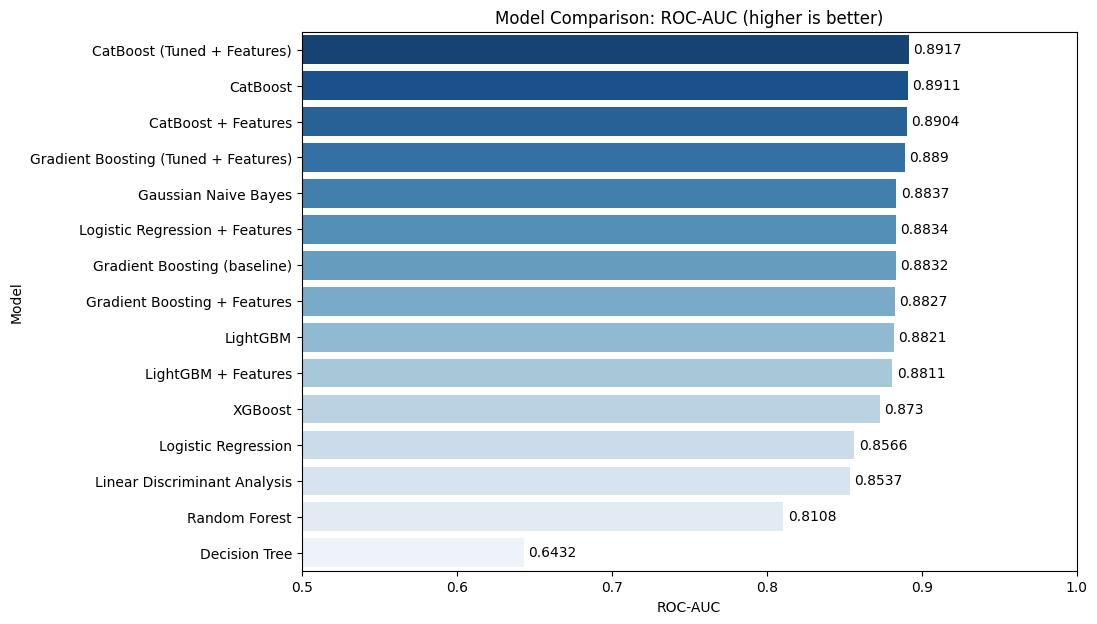

In [113]:
plt.figure(figsize=(10, 7))
ax = sns.barplot(x='ROC-AUC', y='Model', data=comparison, palette='Blues_r')
plt.xlim(0.5, 1.0)
plt.title("Model Comparison: ROC-AUC (higher is better)")
for i, v in enumerate(comparison['ROC-AUC']):
    ax.text(v + 0.003, i, str(v), va='center')
plt.show()

### **10.3 ROC Curves of the Top Models**
Only the top 5 models are plotted, so the chart stays readable. The curve closer to the top-left corner is better, and the dashed line is a random guess.

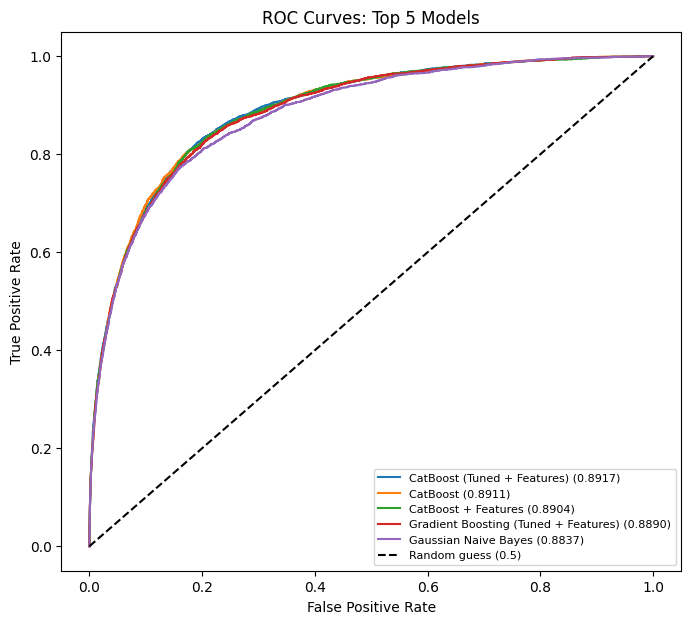

In [114]:
top_models = comparison['Model'].head(5).tolist()

plt.figure(figsize=(8, 7))
for name in top_models:
    fpr, tpr, _ = roc_curve(y_val, probas[name])
    plt.plot(fpr, tpr, label=f"{name} ({roc_auc_score(y_val, probas[name]):.4f})")
plt.plot([0, 1], [0, 1], 'k--', label='Random guess (0.5)')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves: Top 5 Models")
plt.legend(fontsize=8)
plt.show()

### **10.4 Precision-Recall Curve of the Top Models**
For imbalanced data the Precision-Recall curve is more sensitive than the ROC curve, because it focuses on the rare class 1.

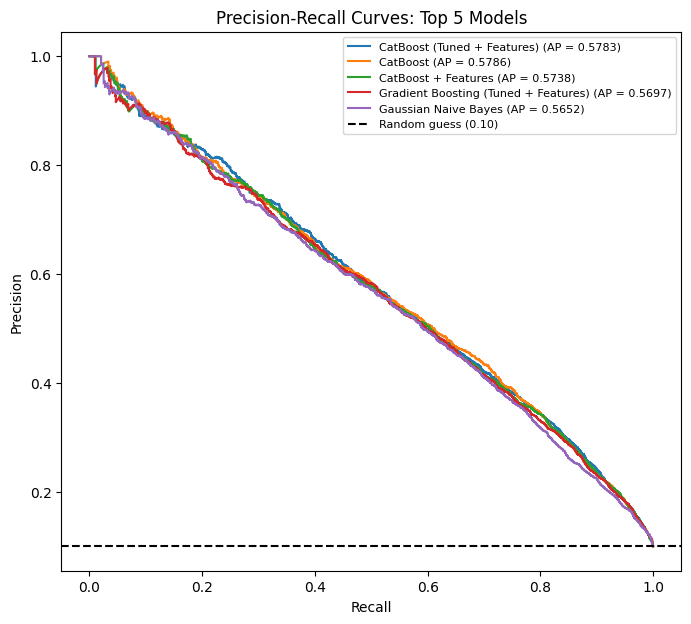

In [115]:
from sklearn.metrics import precision_recall_curve

plt.figure(figsize=(8, 7))
for name in top_models:
    prec, rec, _ = precision_recall_curve(y_val, probas[name])
    plt.plot(rec, prec, label=f"{name} (AP = {average_precision_score(y_val, probas[name]):.4f})")
plt.axhline(y_val.mean(), color='k', linestyle='--', label=f'Random guess ({y_val.mean():.2f})')
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves: Top 5 Models")
plt.legend(fontsize=8)
plt.show()

### **10.5 Detailed Report of the Best Model**
The classification report and confusion matrix use the threshold that gave the best F1-score for this model.

In [116]:
# Evaluate the selected model on the VALIDATION dataset
best_name = comparison.loc[1, 'Model']
best_p = probas[best_name]
best_th = float(comparison.loc[1, 'Threshold'])
best_pred = (best_p >= best_th).astype(int)

print("Best model:", best_name)
print("Selected threshold:", best_th)
print("\nVALIDATION SET CLASSIFICATION REPORT")
print(classification_report(
    y_val,
    best_pred,
    target_names=['No Transaction', 'Transaction']
))

Best model: CatBoost (Tuned + Features)
Selected threshold: 0.71

VALIDATION SET CLASSIFICATION REPORT
                precision    recall  f1-score   support

No Transaction       0.95      0.94      0.95     26985
   Transaction       0.53      0.57      0.55      3015

      accuracy                           0.91     30000
     macro avg       0.74      0.76      0.75     30000
  weighted avg       0.91      0.91      0.91     30000



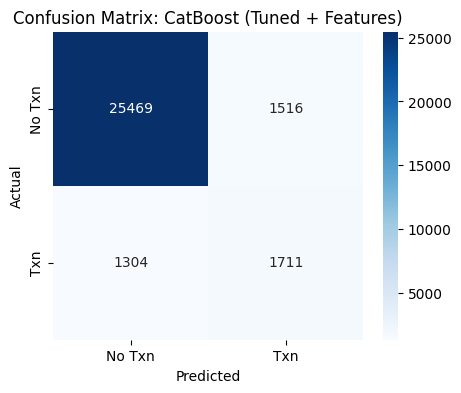

True Negatives  (correctly said no transaction): 25469
False Positives (said transaction, but no)     : 1516
False Negatives (missed a real transaction)    : 1304
True Positives  (correctly found transaction)  : 1711


In [117]:
cm = confusion_matrix(y_val, best_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Txn', 'Txn'], yticklabels=['No Txn', 'Txn'])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix: " + best_name)
plt.show()

tn, fp, fn, tp = cm.ravel()
print("True Negatives  (correctly said no transaction):", tn)
print("False Positives (said transaction, but no)     :", fp)
print("False Negatives (missed a real transaction)    :", fn)
print("True Positives  (correctly found transaction)  :", tp)

### 10.6 Model Comparison Report: Summary

**1. Which model performed best?**

**CatBoost (Tuned + Features)** achieved the highest ROC-AUC of **0.8917** on the validation dataset. It also achieved an Average Precision of **0.5783**, Recall of **0.5675**, Precision of **0.5302**, and F1-score of **0.5482**.

**2. How do the other models compare?**

- **CatBoost** was the second-best model, with a ROC-AUC of 0.8911.
- **CatBoost + Features** achieved a ROC-AUC of 0.8904.
- **Gradient Boosting (Tuned + Features)** achieved a ROC-AUC of 0.8890.
- **Gaussian Naive Bayes** achieved a ROC-AUC of 0.8837 and was the fastest model.
- **Decision Tree** had the lowest ROC-AUC of 0.6432.

**3. What improved the models?**

Feature engineering and hyperparameter tuning were evaluated to improve model performance. The results show that CatBoost with tuning and engineered features achieved the highest validation ROC-AUC among the compared models.

**4. Why is accuracy not used to choose the model?**

The dataset is imbalanced, with approximately 90% of customers belonging to class 0 and 10% to class 1. A model could achieve high accuracy by mostly predicting the majority class. Therefore, ROC-AUC is used as the main model-selection metric, with Precision, Recall, F1-score, and Average Precision as supporting metrics.

**5. Trade-off to consider**

CatBoost requires more training time than simpler models. However, it provides the best validation ROC-AUC among the evaluated models. The final model is therefore selected based on its predictive performance rather than training speed alone.

### 10.7 Recommended Model for Production

**Recommendation: CatBoost (Tuned + Features)**

Based on the validation results, CatBoost (Tuned + Features) is selected as the recommended model for production.

**Reasons for Selection**

- **Strong predictive performance:** It achieved the highest ROC-AUC among the evaluated models on the validation dataset.
- **Class imbalance handling:** CatBoost supports class weighting, which helps the model learn from the minority class (customers who make transactions).
- **Feature handling:** It can effectively learn complex patterns from the original and engineered features.
- **Robustness:** It uses multiple decision trees to capture non-linear relationships in the dataset.
- **Production suitability:** The trained model can be saved and reused to predict transactions for new customers.

**Final Recommendation**

CatBoost (Tuned + Features) is selected as the final model because it provides the best validation performance among the models evaluated. Its performance is further assessed using the separate test dataset before considering production deployment.

## **11. Final Model for Production**

The selected model is **CatBoost (Tuned + Features)**. For the final model we:

1. Retrain it using **85% of the complete dataset (170,000 records)** by combining the original training and validation datasets.
2. Keep the remaining **15% (30,000 records)** reserved for independent testing.
3. Save the model and the settings needed to use it.
4. Show how to predict for new customers.

**The final CatBoost model was retrained using 85% of the complete dataset (170,000 records), while the remaining 15% (30,000 records) was reserved for independent testing.**

The held-out test dataset is not used during model training or hyperparameter selection. It is used only for the final performance evaluation.

### **11.1 Retrain the Best Model on Training + Validation Data**

After selecting CatBoost (Tuned + Features) as the best-performing model, we retrain it using the combined training and validation datasets.

- **Training dataset:** 140,000 records.
- **Validation dataset:** 30,000 records.
- **Combined training dataset:** 170,000 records.
- **Reserved test dataset:** 30,000 records.

The best hyperparameters and the optimal number of iterations obtained during model tuning are used to train the final model.

The test dataset is kept completely separate and is used only for the final performance evaluation. This provides an unbiased assessment of the model's ability to predict transactions for unseen customers.

In [118]:

print("Best parameters:", best_cat_params)
print("Trees          :", best_cat_iter)

# Combine training and validation datasets
X_final = pd.concat([
    X_B.loc[train_idx],
    X_B.loc[val_idx]
])

y_final = np.concatenate([y_train, y_val])

# Initialize the final CatBoost model
t = time.time()

final_model = CatBoostClassifier(
    iterations=best_cat_iter,
    auto_class_weights='Balanced',
    verbose=200,
    random_seed=42,
    **best_cat_params
)

# Train using training + validation data only
final_model.fit(X_final, y_final)

print("\nTraining time (sec):", round(time.time() - t, 1))
print("Training records:", len(y_final))
print("Reserved test records:", len(y_test))


Best parameters: {'learning_rate': 0.05, 'depth': 4}
Trees          : 1937
0:	learn: 0.6903546	total: 370ms	remaining: 11m 55s
200:	learn: 0.5370287	total: 45s	remaining: 6m 28s
400:	learn: 0.4803502	total: 1m 31s	remaining: 5m 49s
600:	learn: 0.4465347	total: 2m 18s	remaining: 5m 7s
800:	learn: 0.4230913	total: 3m 5s	remaining: 4m 23s
1000:	learn: 0.4050986	total: 3m 52s	remaining: 3m 37s
1200:	learn: 0.3904473	total: 4m 40s	remaining: 2m 51s
1400:	learn: 0.3779512	total: 5m 26s	remaining: 2m 5s
1600:	learn: 0.3668854	total: 6m 14s	remaining: 1m 18s
1800:	learn: 0.3568809	total: 7m 1s	remaining: 31.9s
1936:	learn: 0.3504482	total: 7m 33s	remaining: 0us

Training time (sec): 462.0
Training records: 170000
Reserved test records: 30000


### 11.2 Final Evaluation on the Unseen Test Dataset

After training the final CatBoost model using the combined training and validation datasets, we evaluate its performance on the reserved test dataset containing 30,000 unseen customer records.

The classification threshold selected using the validation dataset is applied to the test predictions. The test dataset is not used for model training, hyperparameter tuning or threshold selection.

The following evaluation metrics are used:

- **ROC-AUC:** Measures the model's ability to distinguish between customers who will transact and those who will not.
- **Average Precision:** Evaluates precision and recall for the minority class.
- **Accuracy:** Measures the overall percentage of correct predictions.
- **Precision:** Measures how many customers predicted to transact actually transact.
- **Recall:** Measures how many actual transacting customers are correctly identified.
- **F1-score:** Represents the balance between precision and recall.

The confusion matrix and classification report are also generated to provide a detailed understanding of the model's performance on unseen data.

FINAL TEST SET RESULTS
----------------------
ROC-AUC: 0.8941
Average Precision: 0.6003
Accuracy: 0.9133
Precision: 0.5709
Recall: 0.5501
F1-Score: 0.5603

TEST SET CLASSIFICATION REPORT
                precision    recall  f1-score   support

No Transaction       0.95      0.95      0.95     26986
   Transaction       0.57      0.55      0.56      3014

      accuracy                           0.91     30000
     macro avg       0.76      0.75      0.76     30000
  weighted avg       0.91      0.91      0.91     30000



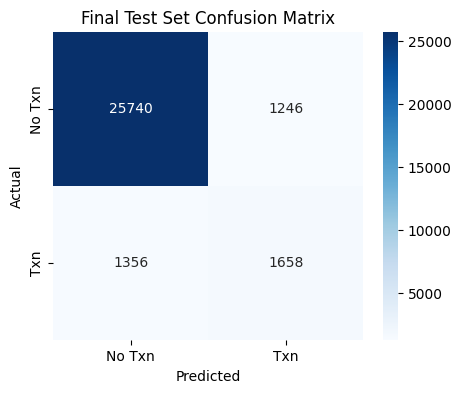

In [123]:

# 11.2 Final evaluation on the unseen TEST dataset

# Prepare test features
X_test_final = X_B.loc[test_idx]

# Predict probabilities
test_proba = final_model.predict_proba(X_test_final)[:, 1]

# Use the threshold selected on the validation dataset
test_pred = (test_proba >= best_th).astype(int)

# Calculate final test metrics
print("FINAL TEST SET RESULTS")
print("----------------------")
print("ROC-AUC:", round(roc_auc_score(y_test, test_proba), 4))
print("Average Precision:",
      round(average_precision_score(y_test, test_proba), 4))
print("Accuracy:", round(accuracy_score(y_test, test_pred), 4))
print("Precision:", round(precision_score(y_test, test_pred), 4))
print("Recall:", round(recall_score(y_test, test_pred), 4))
print("F1-Score:", round(f1_score(y_test, test_pred), 4))

print("\nTEST SET CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    test_pred,
    target_names=['No Transaction', 'Transaction']
))

# Confusion matrix
cm_test = confusion_matrix(y_test, test_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(
    cm_test,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Txn', 'Txn'],
    yticklabels=['No Txn', 'Txn']
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Final Test Set Confusion Matrix")
plt.show()


### 11.3 Top 15 Most Important Features

Feature importance is used to identify the features that contribute most to the predictions made by the final CatBoost model.

The CatBoost model provides feature importance scores that indicate the relative contribution of each input feature to the model's predictions.

In this section, the top 15 most important features are extracted and visualized using a horizontal bar chart.

**Objectives:**

- Identify the most influential features used by the model.
- Understand which features contribute more to transaction prediction.
- Visualize the top 15 features for better interpretation.
- Gain insights into the patterns learned by the CatBoost model.

Feature importance helps identify which anonymized input variables contribute most to the model's predictions. Since the original feature names and their business meanings are not available, these importance scores cannot be directly interpreted as actual customer behaviour or causal factors. However, they provide useful insights into how the model uses different features to make transaction predictions.

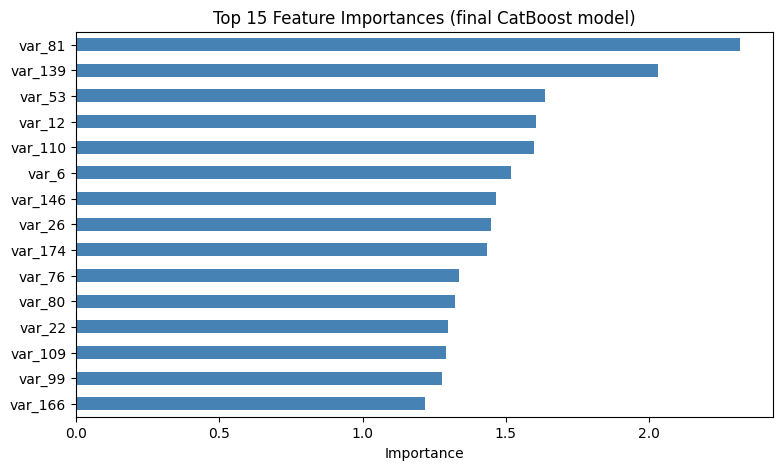

Importance share of '_uniq' features: 1.7 %


In [119]:
importance = pd.Series(final_model.get_feature_importance(), index=X_B.columns).sort_values(ascending=False)

plt.figure(figsize=(9, 5))
importance.head(15).sort_values().plot(kind='barh', color='steelblue')
plt.title("Top 15 Feature Importances (final CatBoost model)")
plt.xlabel("Importance")
plt.show()

print("Importance share of '_uniq' features:",
      round(importance[importance.index.str.endswith('_uniq')].sum() / importance.sum() * 100, 1), "%")

### **11.4 Save the Model**
We save the model, the threshold and the list of feature columns, so the model can be reused without retraining.

In [124]:

# Save the final CatBoost model
final_model.save_model("customer_transaction_model.cbm")

# Save settings and training reference frequencies
settings = {
    'threshold': best_th,
    'feature_columns': list(X_B.columns),
    'reference_counts': reference_counts
}

joblib.dump(settings, "model_settings.pkl")

print("Model and settings saved successfully.")
print("Threshold:", best_th)
print("Feature columns:", len(X_B.columns))


Model and settings saved successfully.
Threshold: 0.71
Feature columns: 400


### **11.5 Predict for New Customers**

New customers must go through the **same feature engineering** as the training data. The "occurs only once" feature depends on how often a value appears in its column. These frequency counts are calculated using the **training customers only** and stored as reference counts.

During prediction, the saved training reference counts are reused to generate the `_uniq` features. The original feature value is retained only when its frequency in the training data is exactly one; otherwise, it is replaced with a missing value (`NaN`).

The training data and new customer data are **not combined to recalculate frequency counts**. This ensures consistency between training and prediction. No target value is needed for prediction.

In [125]:

def prepare_features(new_data, reference_counts, feature_columns):
    new_data = new_data.astype('float32')

    # Apply the same training reference frequencies
    counts = pd.DataFrame({
        col: new_data[col].map(reference_counts[col])
        for col in new_data.columns
    }, index=new_data.index)

    # Create the unique-value features
    features = pd.concat([
        new_data,
        new_data.where(counts == 1).add_suffix('_uniq')
    ], axis=1)

    return features[feature_columns]


def predict_customers(new_data):
    model = CatBoostClassifier()
    model.load_model("customer_transaction_model.cbm")

    cfg = joblib.load("model_settings.pkl")

    features = prepare_features(
        new_data,
        cfg['reference_counts'],
        cfg['feature_columns']
    )

    probabilities = model.predict_proba(features)[:, 1]

    return pd.DataFrame({
        'Probability of Transaction': probabilities.round(3),
        'Prediction': (probabilities >= cfg['threshold']).astype(int)
    }, index=new_data.index)


In [127]:

# Select 5 customers from the unseen test dataset
sample = X_test.iloc[:5]

# Generate predictions
out = predict_customers(sample)

# Add customer IDs and actual values
out['ID_code'] = ids.loc[sample.index].values
out['Actual'] = y_test[:5]

display(
    out[
        ['ID_code', 'Probability of Transaction',
         'Prediction', 'Actual']
    ].reset_index(drop=True)
)


,ID_code,Probability of Transaction,Prediction,Actual
0,train_145439,0.337,0,0
1,train_177157,0.050,0,0
2,train_20612,0.234,0,0
3,train_37604,0.335,0,0
4,train_114026,0.458,0,1


### **11.6 Observations**

**1. Final Model Training**

The final CatBoost model was trained using the combined training and validation datasets, containing 170,000 customer records. The separate test dataset containing 30,000 records was reserved for final evaluation.

**2. Model Performance on the Test Dataset**

The final model achieved the following results on unseen test data:

| Evaluation Metric | Test Score |
|---|---:|
| ROC-AUC | 0.8941 |
| Average Precision | 0.6003 |
| Accuracy | 0.9133 |
| Precision | 0.5709 |
| Recall | 0.5501 |
| F1-score | 0.5603 |

**3. Prediction Results**

The prediction function was tested using five customer records from the unseen test dataset. It successfully generated transaction probabilities and binary predictions.

In the sample:
- Four customers who did not transact were correctly predicted as class 0.
- One customer who actually transacted was predicted as class 0.

This demonstrates that the prediction function works, although a small sample cannot represent overall model performance.

**4. Model Saving and Reusability**

The trained CatBoost model and its configuration settings were saved successfully. These include the classification threshold, feature columns and reference frequency information.

**5. Overall Observation**

The model demonstrates good discrimination ability on unseen customer data, with a test ROC-AUC of 0.8941. However, further improvements in identifying actual transacting customers may be useful, particularly to improve recall.


## **12. Discussions and Recommendations**

### **12.1 Discussion**

**1. Nature of the Data**

The dataset contains 200,000 customer records and 200 anonymized numerical features, with no missing values or duplicate records. The features show relatively weak correlations with one another, and their individual relationships with the target variable are also weak. This suggests that the predictive signal is distributed across multiple features rather than being strongly represented by a single feature.

**2. Class Imbalance**

Approximately 90% of customers belong to Class 0 (No Transaction), while only about 10% belong to Class 1 (Transaction). Therefore, accuracy alone is not a reliable measure of model performance, because always predicting the majority class would already achieve approximately 90% accuracy.

Class imbalance was addressed using stratified data splitting and model-specific class weighting or sample weighting wherever supported. Gaussian Naive Bayes and Linear Discriminant Analysis were implemented without class weights. Classification threshold tuning and metrics such as ROC-AUC and Average Precision were also used to evaluate model performance.

**3. Model Performance**

- Simpler models also produced competitive results. Gaussian Naive Bayes achieved a validation ROC-AUC of **0.8837**, demonstrating that a relatively simple probabilistic model can capture useful patterns in this dataset.
- Boosting models generally performed better than tree-based baseline models. Random Forest achieved a ROC-AUC of **0.8108**, while a single Decision Tree achieved **0.6432**.
- Feature engineering improved the performance of some models. Logistic Regression + Features achieved a validation ROC-AUC of **0.8834**.
- **Hyperparameter tuning improved the boosting models:** Gradient Boosting increased from 0.8827 to **0.8890**, while CatBoost increased from 0.8904 to **0.8917**.
- CatBoost achieved the highest validation ROC-AUC among the evaluated model configurations, although its improvement after tuning was relatively small.

**4. Final Model**

**CatBoost (Tuned + Features)** was selected as the final model based on its validation performance.

Its validation results were:

| Metric | Validation Score |
|---|---:|
| ROC-AUC | 0.8917 |
| Average Precision | 0.5783 |
| Recall | 0.5675 |
| Precision | 0.5302 |
| F1-score | 0.5482 |
| Accuracy | 0.9060 |

The final model was retrained using 170,000 records (85% of the complete dataset), while 30,000 records (15%) were reserved for independent testing.

On the independent test dataset, CatBoost achieved a ROC-AUC of **0.8941**, Average Precision of **0.6003**, Recall of **0.5501**, Precision of **0.5709**, F1-score of **0.5603**, and Accuracy of **0.9133**.

These results indicate that the model can distinguish between customers who are likely to transact and those who are not. However, it still misses some actual transaction customers and produces some false-positive predictions.

**5. Limitations**

- Hyperparameters and the classification threshold were selected using the validation dataset. Therefore, validation scores may be selection-optimized, and independent test performance provides a more reliable estimate of generalization.
- The features are anonymized, making it difficult to explain the model's predictions in terms of actual banking and customer behaviour.
- The final test ROC-AUC of 0.8941 and F1-score of 0.5603 indicate promising predictive performance, but the model still has room for improvement in identifying transaction customers.
- The tuned CatBoost model required approximately **384.6 seconds** during hyperparameter tuning, making training more computationally expensive than simpler models.
- The engineered unique-value-only features depend on reference frequencies calculated from the training data. These saved training reference frequencies must be reused when generating features for new customers.
- The classification threshold of 0.71 was selected using validation data and applied unchanged to the held-out test set. The test set was not used to select or adjust the threshold, ensuring an unbiased evaluation of the final model. If the model is retrained or deployed in a different setting, the threshold can be reassessed using a separate validation dataset and relevant business requirements.

### **12.2 Recommendations**

**For the Bank**

1. **Use CatBoost (Tuned + Features) as the primary candidate model.** Gradient Boosting (Tuned + Features), with a validation ROC-AUC of **0.8890**, can be retained as an alternative model.
2. **Use predicted probabilities to rank customers.** Focus marketing campaigns on customers with higher predicted transaction probabilities rather than relying only on binary predictions.
3. **Review the classification threshold with business teams.** The threshold of **0.71** was selected using validation data. If missing a potential transaction customer is more costly than contacting an uninterested customer, a lower threshold may improve Recall. If campaign costs are high, a higher threshold may improve Precision.
4. **Do not evaluate the model using accuracy alone.** Report ROC-AUC, Average Precision, Precision, Recall, and F1-score to provide a more complete picture of model performance.
5. **Monitor model performance after deployment.** Track performance on new customer data and retrain the model when changes in customer behaviour or data distributions are observed.
6. **Conduct a pilot study before full deployment.** A small pilot or A/B test can help determine whether targeting customers using predicted probabilities improves transaction outcomes compared with a suitable control group.

**For Improving the Project**

1. **Obtain meaningful feature descriptions.** Access to the original feature names and their business meanings would improve interpretability and support more meaningful feature engineering.
2. **Use cross-validation during model development.** Cross-validation can provide a more reliable estimate of model performance, while a separate untouched test dataset should remain reserved for final evaluation.
3. **Explore additional feature engineering techniques.** More feature combinations, transformations, and feature-selection methods could help identify useful patterns.
4. **Explore ensemble methods.** Combining CatBoost, Gradient Boosting, and other suitable models may improve predictive performance, although any improvement must be verified using independent evaluation.
5. **Apply model explainability techniques.** SHAP values can help understand feature contributions and improve transparency, even when the original feature meanings are limited.
6. **Evaluate probability calibration.** Calibration techniques can help ensure that predicted probabilities better reflect actual transaction likelihoods.
7. **Reassess the classification threshold after final retraining.** If the model is retrained or deployed in a different setting, reassess the threshold using a separate validation dataset and the bank's business requirements. Do not use the held-out test set for threshold selection.



## **13. Challenges Faced**

During the development of the Customer Transaction Prediction project, several challenges were encountered. Different techniques were applied to address these challenges and improve the reliability and performance of the machine learning models.

### **13.1 Anonymized Features**

- **Challenge:** The dataset contains 200 anonymized numerical features (`var_0` to `var_199`). Their actual business meanings are unknown, making feature interpretation and domain-based feature selection difficult.
- **Solution:** Exploratory Data Analysis (EDA) was performed to understand feature distributions, correlations, outliers and repeated values. Statistical properties were used to guide feature engineering and model selection.

### **13.2 Imbalanced Target Variable**

- **Challenge:** Approximately 90% of customers belong to class 0 (No Transaction), while only 10% belong to class 1 (Transaction). This makes it difficult for models to identify the minority class.
- **Solution:** Stratified splitting and class-weighting techniques were used. ROC-AUC, Precision, Recall, F1-score and Average Precision were considered instead of relying only on accuracy.
- **Additional consideration:** The classification threshold was selected using validation data to balance Precision and Recall.
- **Why SMOTE was not used:** Class weighting was preferred to retain the original observations and avoid introducing potentially noisy synthetic samples in the 200-dimensional feature space.

### **13.3 Weak Relationship Between Features and Target**

- **Challenge:** Individual features showed relatively weak relationships with the target variable, making transaction prediction difficult.
- **Solution:** Feature engineering techniques were applied to capture additional patterns. Squared features and duplicate-value indicators were explored for Logistic Regression, while unique-value-only features were used with boosting models.

### **13.4 Large Dataset and Memory Management**

- **Challenge:** The dataset contains 200,000 records and 200 numerical features. Feature engineering increased the number of columns to 400–600, increasing memory requirements.
- **Solution:** Numerical features were converted to `float32` where appropriate. Unnecessary dataframes were deleted after use, and `gc.collect()` was used to release unused memory.

### **13.5 High Computational Cost of Some Algorithms**

- **Challenge:** Some machine learning algorithms require significant training time when applied to large datasets. Random Forest required considerable training time, while KNN and kernel SVM were expected to be computationally expensive.
- **Solution:** Computationally expensive models were limited or skipped. Parallel processing was used where supported, and boosting models were tuned using early stopping to reduce unnecessary training.

### **13.6 Handling Outliers**

- **Challenge:** Extreme values were present in some numerical features, making it necessary to determine whether they could negatively affect model performance.
- **Solution:** The Interquartile Range (IQR) method was used to detect and analyze outliers in the numerical features. The analysis showed that the average proportion of outliers was approximately 0.07%, with a maximum of around 0.75% in an individual feature. Since the proportion was very low and the extreme values could represent genuine customer transaction patterns, they were retained without applying outlier removal or capping.
- **Reason:** Removing or modifying these observations could result in the loss of potentially useful information.

### **13.7 Preventing Data Leakage**

- **Challenge:** Using information from validation or test data during preprocessing, feature engineering or model training can lead to overly optimistic evaluation results.
- **Solution:** The dataset was divided into stratified training, validation and test subsets. The scaler was fitted using training data only. Feature-frequency reference counts were calculated using training data only and then applied consistently to all datasets. The test dataset was kept separate from model training, hyperparameter selection and classification threshold selection.

### **13.8 Missing Values in Engineered Features**

- **Challenge:** Some unique-value-only features created during feature engineering contain missing values by design.
- **Solution:** These engineered features were used with models that support missing values, such as CatBoost, rather than applying unnecessary imputation.

### **13.9 Overfitting and Hyperparameter Selection**

- **Challenge:** Selecting too few trees can lead to underfitting, while too many trees can increase training time and risk overfitting.
- **Solution:** Hyperparameter tuning and early stopping were used to identify suitable model configurations. Learning rate, number of iterations and other parameters were adjusted to improve validation performance.

### **13.10 Selecting an Appropriate Classification Threshold**

- **Challenge:** The default threshold of 0.5 may not provide the best balance between Precision and Recall for an imbalanced classification problem.
- **Solution:** Different probability thresholds were evaluated using validation predictions. The threshold of 0.71, which maximized the validation F1-score for the selected CatBoost model, was applied unchanged to the independent test dataset. The test dataset was not used for threshold selection or adjustment.

### **13.11 Overall Learning from the Challenges**

The project highlighted the importance of proper data preprocessing, feature engineering, class-imbalance handling, computational efficiency and leakage-free model evaluation.

Addressing these challenges helped develop a more reliable customer transaction prediction model and provided practical experience in building an end-to-end machine learning solution.



## **14. Final Conclusion**

This project focused on predicting whether a bank customer is likely to make a future transaction using machine learning techniques. The dataset contained 200,000 customer records with 200 anonymized numerical features and an imbalanced binary target variable.

### **1. Data Analysis and Preprocessing**

Exploratory Data Analysis revealed that the dataset contained no missing values or duplicate records. The numerical features showed relatively weak correlations with one another and weak individual relationships with the target variable. The target distribution was imbalanced, with approximately 89.95% of records belonging to Class 0 and 10.05% belonging to Class 1.

Outliers were identified using the Interquartile Range (IQR) method. Since their average proportion was very low, they were retained without removal or capping.

### **2. Feature Engineering**

Two feature sets were developed to improve model performance.

- **Feature Set A:** Included 200 original features, 200 squared features, and 200 duplicate flags, resulting in 600 features.
- **Feature Set B:** Included 200 original features and 200 unique-value-only features, resulting in 400 features.

These engineered features provided additional information that could help machine learning models identify patterns in customer transaction behaviour.

### **3. Model Development and Comparison**

A total of 15 model configurations were trained and evaluated using the validation dataset. The experiments included baseline models, feature-engineered models, and hyperparameter-tuned models.

Among the evaluated models, Gaussian Naive Bayes achieved a validation ROC-AUC of 0.8837, while Logistic Regression + Features achieved 0.8834. Random Forest and Decision Tree achieved comparatively lower scores of 0.8108 and 0.6432, respectively.

Hyperparameter tuning improved the performance of the boosting models. CatBoost improved from a ROC-AUC of 0.8904 to 0.8917, while Gradient Boosting improved from 0.8827 to 0.8890.

### **4. Final Model Selection**

**CatBoost (Tuned + Features)** was selected as the best model based on its validation performance.

Its validation results were:

| Metric | Validation Score |
|---|---:|
| ROC-AUC | 0.8917 |
| Average Precision | 0.5783 |
| Precision | 0.5302 |
| Recall | 0.5675 |
| F1-score | 0.5482 |
| Accuracy | 0.9060 |

The model achieved the highest validation ROC-AUC among the evaluated configurations, making it the selected candidate for final testing.

### **5. Independent Test Evaluation**

The final CatBoost model was retrained using the combined training and validation datasets, containing 170,000 records (85% of the complete dataset). The remaining 30,000 records (15%) were reserved for independent testing.

The final test results were:

| Metric | Test Score |
|---|---:|
| ROC-AUC | 0.8941 |
| Average Precision | 0.6003 |
| Precision | 0.5709 |
| Recall | 0.5501 |
| F1-score | 0.5603 |
| Accuracy | 0.9133 |

The test ROC-AUC of 0.8941 demonstrates that the model has a good ability to distinguish between customers who make transactions and those who do not. Its recall of 55.01% indicates that it identifies approximately 55% of actual transaction customers, while its precision of 57.09% indicates that approximately 57% of its positive predictions are correct.

### **6. Limitations and Future Improvements**

Although the model achieved promising results, some limitations remain:

- The anonymized features make it difficult to interpret predictions in terms of actual customer behaviour.
- The imbalanced target distribution continues to affect the identification of minority-class customers.
- The model does not identify all customers who make future transactions, as reflected by its test recall.
- The model was evaluated using a single independent test split. Further evaluation on future customer data would help assess its reliability over time.
- The classification threshold of 0.71 was selected using validation data and applied unchanged during independent testing. Any future threshold adjustments should be based on a separate validation dataset and the bank's business requirements, without using the held-out test set.

Future improvements could include probability calibration, explainability techniques such as SHAP, additional feature selection, threshold optimization, and continuous monitoring of model performance.

### **7. Final Statement**

Overall, the project successfully demonstrated a complete machine learning workflow, including exploratory data analysis, data preprocessing, feature engineering, model development, hyperparameter tuning, model comparison, and independent testing.

The final CatBoost model achieved a ROC-AUC of **0.8941** and an accuracy of **91.33%** on the independent test dataset. These results demonstrate the potential of machine learning techniques for predicting future customer transactions and supporting data-driven customer targeting.

The project also highlights the importance of selecting appropriate evaluation metrics, handling class imbalance, and maintaining an independent test dataset to obtain a reliable estimate of model performance.



# **15. Project Links**

The following links provide access to the complete project resources, including the source code, Jupyter Notebook, dataset, trained models, project presentation, and supporting documentation.

## **1. GitHub Repository**

The GitHub repository contains the project source code, Jupyter Notebook, README file, and other related project files.

**GitHub Repository:**  
[Customer Transaction Prediction – GitHub](https://github.com/IswaryaGudi/PRCP-1003-Customer-Transaction-Prediction)

---

## **2. Google Drive**

The Google Drive folder provides access to the project presentation (PPT) and final project report.

**Google Drive:**  
[Customer Transaction Prediction – Project Resources](https://drive.google.com/drive/u/0/folders/13z8tqe0QWeljh7TijLNHzxIvvq_MWMBM)

---
